In [23]:
import warnings, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
pd.set_option("display.max_colwidth", None)

MANUAL_PATH = None

from pathlib import Path
FILE = "weatherHistory.csv"
candidates = [Path(MANUAL_PATH)] if MANUAL_PATH else []
candidates += [Path(FILE), Path.home()/"Downloads"/FILE, Path.home()/"Desktop"/FILE, Path.home()/"Documents"/FILE]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(f"{FILE} not found. Current folder: {os.getcwd()}. "
                            "Copy the CSV into that folder or set MANUAL_PATH above.")
print("Using data file:", DATA_PATH)

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Using data file: C:\Users\Asus\Downloads\weatherHistory.csv
Shape: (96453, 12)


,Formatted Date,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Loud Cover,Pressure (millibars),Daily Summary
0,2006-04-01 00:00:00.000 +0200,Partly Cloudy,rain,9.472222,7.388889,0.89,14.1197,251.0,15.8263,0.0,1015.13,Partly cloudy throughout the day.
1,2006-04-01 01:00:00.000 +0200,Partly Cloudy,rain,9.355556,7.227778,0.86,14.2646,259.0,15.8263,0.0,1015.63,Partly cloudy throughout the day.
2,2006-04-01 02:00:00.000 +0200,Mostly Cloudy,rain,9.377778,9.377778,0.89,3.9284,204.0,14.9569,0.0,1015.94,Partly cloudy throughout the day.
3,2006-04-01 03:00:00.000 +0200,Partly Cloudy,rain,8.288889,5.944444,0.83,14.1036,269.0,15.8263,0.0,1016.41,Partly cloudy throughout the day.
4,2006-04-01 04:00:00.000 +0200,Mostly Cloudy,rain,8.755556,6.977778,0.83,11.0446,259.0,15.8263,0.0,1016.51,Partly cloudy throughout the day.


In [24]:
print("Missing values before cleaning:\n", df.isnull().sum()[df.isnull().sum() > 0], "\n")
print("Duplicate rows:", df.duplicated().sum())

df["Precip Type"] = df["Precip Type"].ffill()
df["Suitability"] = (df["Summary"] == "Clear").astype(int)
df = df.drop_duplicates()        
df = pd.get_dummies(df, columns=["Precip Type"], prefix="Precip", dtype=int)
df = df.drop(columns=["Formatted Date", "Summary", "Daily Summary", "Loud Cover"])
df = df.rename(columns={
    "Temperature (C)": "Temperature", "Apparent Temperature (C)": "Apparent_Temperature",
    "Wind Speed (km/h)": "Wind_Speed", "Wind Bearing (degrees)": "Wind_Bearing",
    "Visibility (km)": "Visibility", "Pressure (millibars)": "Pressure",
    "Precip_rain": "Precip_Rain", "Precip_snow": "Precip_Snow"})

print("Final shape:", df.shape)
print("Missing values after cleaning:", int(df.isnull().sum().sum()))
df.head()

Missing values before cleaning:
 Precip Type    517
dtype: int64 

Duplicate rows: 24
Final shape: (96429, 10)
Missing values after cleaning: 0


,Temperature,Apparent_Temperature,Humidity,Wind_Speed,Wind_Bearing,Visibility,Pressure,Suitability,Precip_Rain,Precip_Snow
0,9.472222,7.388889,0.89,14.1197,251.0,15.8263,1015.13,0,1,0
1,9.355556,7.227778,0.86,14.2646,259.0,15.8263,1015.63,0,1,0
2,9.377778,9.377778,0.89,3.9284,204.0,14.9569,1015.94,0,1,0
3,8.288889,5.944444,0.83,14.1036,269.0,15.8263,1016.41,0,1,0
4,8.755556,6.977778,0.83,11.0446,259.0,15.8263,1016.51,0,1,0


Suitability
Not Clear    85556
Clear        10873
Name: count, dtype: int64

Clear share: 0.113
Majority-class baseline accuracy (always predict 'Not Clear'): 0.887


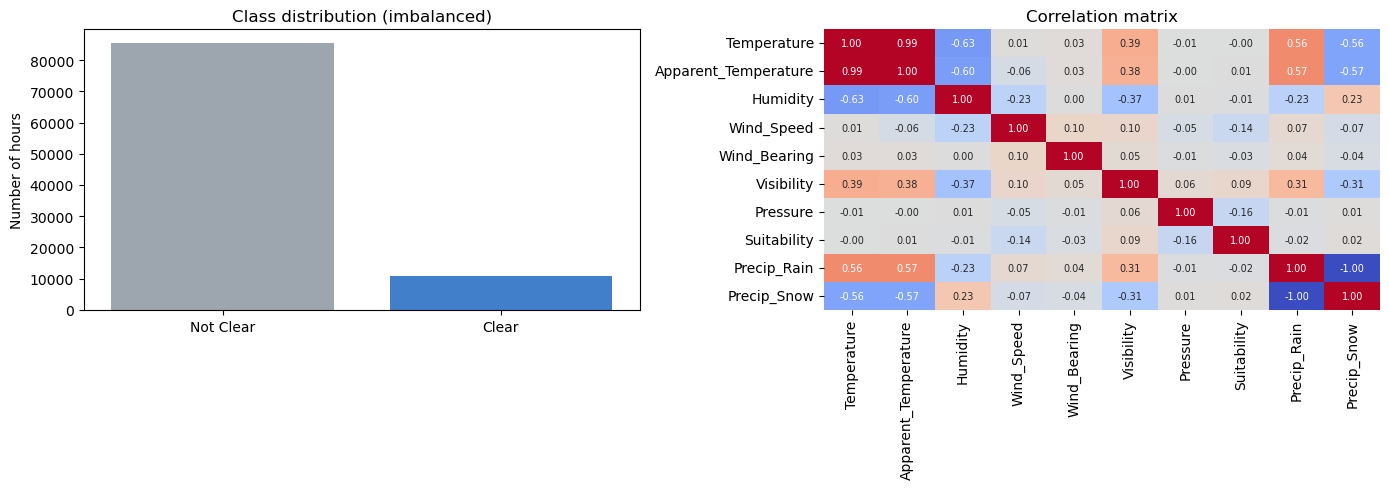

In [25]:
counts = df["Suitability"].value_counts().sort_index()
majority_baseline = counts.max() / counts.sum()
print(counts.rename({0: "Not Clear", 1: "Clear"}))
print(f"\nClear share: {counts[1]/counts.sum():.3f}")
print(f"Majority-class baseline accuracy (always predict 'Not Clear'): {majority_baseline:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=["Not Clear", "Clear"], y=counts.values, ax=ax[0], palette=["#9aa5b1", "#2a7de1"])
ax[0].set_title("Class distribution (imbalanced)"); ax[0].set_ylabel("Number of hours")
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax[1], cbar=False, annot_kws={"size": 7})
ax[1].set_title("Correlation matrix")
plt.tight_layout(); plt.show()


In [26]:
X = df.drop(columns=["Suitability"])
y = df["Suitability"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

print(f"Training samples: {len(X_train)}  |  Testing samples: {len(X_test)}")
print(f"Clear share  train: {y_train.mean():.3f}   test: {y_test.mean():.3f}")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


Training samples: 77143  |  Testing samples: 19286
Clear share  train: 0.113   test: 0.113


In [27]:
num_cols = ["Temperature", "Apparent_Temperature", "Humidity", "Wind_Speed",
            "Wind_Bearing", "Visibility", "Pressure"]

scaler = StandardScaler()
scaler.fit(X_train[num_cols])           

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[num_cols] = scaler.transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

print("Scaled training columns (mean ~0, std ~1):")
display(X_train_scaled[num_cols].agg(["mean", "std"]).round(3))

t_raw = DecisionTreeClassifier(max_depth=10, class_weight="balanced", random_state=RANDOM_STATE).fit(X_train, y_train)
t_scl = DecisionTreeClassifier(max_depth=10, class_weight="balanced", random_state=RANDOM_STATE).fit(X_train_scaled, y_train)
same = np.array_equal(t_raw.predict(X_test), t_scl.predict(X_test_scaled))
print(f"F1 raw: {f1_score(y_test, t_raw.predict(X_test)):.4f} | F1 scaled: {f1_score(y_test, t_scl.predict(X_test_scaled)):.4f} | identical predictions: {same}")

Scaled training columns (mean ~0, std ~1):


,Temperature,Apparent_Temperature,Humidity,Wind_Speed,Wind_Bearing,Visibility,Pressure
mean,0.0,-0.0,0.0,0.0,-0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0


F1 raw: 0.3540 | F1 scaled: 0.3538 | identical predictions: False


In [28]:
def evaluate(model, name, Xtr=X_train, ytr=y_train, Xte=X_test, yte=y_test, fit=True):
    """Fit (optional) and score a model on the hold-out test set."""
    if fit:
        model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)[:, 1]
    p = model.get_params()
    params = (f"max_depth={p['max_depth']}, min_samples_leaf={p['min_samples_leaf']}, "
              f"criterion={p['criterion']}, class_weight={p['class_weight']}") if "max_depth" in p else f"strategy={p.get('strategy')}"
    return {"Model": name, "Parameters": params,
            "Accuracy": accuracy_score(yte, pred),
            "Precision": precision_score(yte, pred, zero_division=0),
            "Recall": recall_score(yte, pred),
            "F1": f1_score(yte, pred),
            "ROC AUC": roc_auc_score(yte, proba)}

# Baseline: a "model" that always predicts the majority class
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
baseline_row = evaluate(baseline, "Baseline (always 'Not Clear')", fit=False)
pd.DataFrame([baseline_row]).round(3)

,Model,Parameters,Accuracy,Precision,Recall,F1,ROC AUC
0,Baseline (always 'Not Clear'),strategy=most_frequent,0.887,0.0,0.0,0.0,0.5


In [29]:
depths = [1, 2, 3, 5, 7, 10, 15, 20, None]
rows = []
for cw in [None, "balanced"]:
    for d in depths:
        m = DecisionTreeClassifier(max_depth=d, class_weight=cw, random_state=RANDOM_STATE)
        s = cross_validate(m, X_train, y_train, cv=cv, n_jobs=-1, return_train_score=True,
                           scoring=["accuracy", "recall", "f1", "roc_auc"])
        rows.append({"class_weight": str(cw), "max_depth": "None" if d is None else d,
                     "CV Accuracy": s["test_accuracy"].mean(), "CV Recall": s["test_recall"].mean(),
                     "CV F1": s["test_f1"].mean(), "CV ROC AUC": s["test_roc_auc"].mean(),
                     "Train F1": s["train_f1"].mean()})
manual = pd.DataFrame(rows)
print("Manual sweep – models trained:", len(manual), "varieties x 5 folds =", len(manual) * 5, "fits")
manual.round(3)

Manual sweep – models trained: 18 varieties x 5 folds = 90 fits


,class_weight,max_depth,CV Accuracy,CV Recall,CV F1,CV ROC AUC,Train F1
0,None,1,0.889,0.067,0.119,0.530,0.119
1,None,2,0.892,0.067,0.122,0.638,0.122
2,None,3,0.893,0.057,0.107,0.683,0.108
3,None,5,0.893,0.064,0.119,0.746,0.122
4,None,7,0.894,0.083,0.150,0.780,0.160
5,None,10,0.893,0.116,0.195,0.787,0.254
6,None,15,0.880,0.210,0.282,0.742,0.564
7,None,20,0.861,0.297,0.324,0.677,0.838
8,None,None,0.845,0.347,0.336,0.628,1.000
9,balanced,1,0.672,0.513,0.261,0.603,0.261


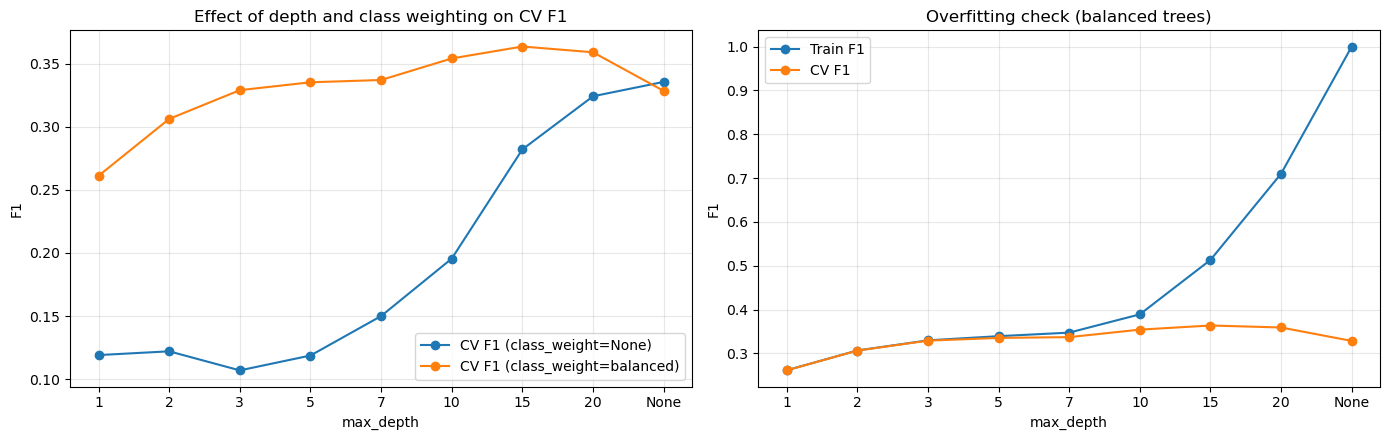

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for cw, g in manual.groupby("class_weight"):
    ax[0].plot(g["max_depth"].astype(str), g["CV F1"], marker="o", label=f"CV F1 (class_weight={cw})")
bal = manual[manual["class_weight"] == "balanced"]
ax[1].plot(bal["max_depth"].astype(str), bal["Train F1"], marker="o", label="Train F1")
ax[1].plot(bal["max_depth"].astype(str), bal["CV F1"], marker="o", label="CV F1")
ax[0].set_title("Effect of depth and class weighting on CV F1")
ax[1].set_title("Overfitting check (balanced trees)")
for a in ax: a.set_xlabel("max_depth"); a.set_ylabel("F1"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

In [31]:
param_grid = {
    "max_depth": [5, 8, 10, 15, 20],
    "min_samples_leaf": [1, 10, 50, 100],
    "criterion": ["gini", "entropy"],
    "class_weight": [None, "balanced"],
}
grid = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), param_grid,
                    cv=cv, scoring="f1", n_jobs=-1, refit=True)
grid.fit(X_train, y_train)

print("Parameter grid searched:")
display(pd.DataFrame({"Parameter": list(param_grid.keys()),
                      "Values tried": [str(v) for v in param_grid.values()],
                      "Count": [len(v) for v in param_grid.values()]}))

n_cfg = len(grid.cv_results_["params"])
print(f"GridSearchCV – {n_cfg} parameter combinations x 5 folds = {n_cfg * 5} model fits")
print("Best parameters :", grid.best_params_)
print(f"Best CV F1      : {grid.best_score_:.4f}")

top = (pd.DataFrame(grid.cv_results_)[["params", "mean_test_score", "std_test_score", "rank_test_score"]]
       .sort_values("rank_test_score").head(8))
top.round(4)

Parameter grid searched:


,Parameter,Values tried,Count
0,max_depth,"[5, 8, 10, 15, 20]",5
1,min_samples_leaf,"[1, 10, 50, 100]",4
2,criterion,"['gini', 'entropy']",2
3,class_weight,"[None, 'balanced']",2


GridSearchCV – 80 parameter combinations x 5 folds = 400 model fits
Best parameters : {'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 20, 'min_samples_leaf': 50}
Best CV F1      : 0.3643


,params,mean_test_score,std_test_score,rank_test_score
58,"{'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 20, 'min_samples_leaf': 50}",0.3643,0.0039,1
54,"{'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 15, 'min_samples_leaf': 50}",0.3642,0.0048,2
74,"{'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 15, 'min_samples_leaf': 50}",0.3639,0.0079,3
52,"{'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 15, 'min_samples_leaf': 1}",0.3635,0.0033,4
78,"{'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 20, 'min_samples_leaf': 50}",0.3635,0.0092,5
53,"{'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 15, 'min_samples_leaf': 10}",0.3605,0.0042,6
72,"{'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 15, 'min_samples_leaf': 1}",0.3603,0.0046,7
73,"{'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 15, 'min_samples_leaf': 10}",0.3600,0.0030,8


In [32]:
best_manual = manual.sort_values("CV F1", ascending=False).iloc[0]
d_manual = None if best_manual["max_depth"] == "None" else int(best_manual["max_depth"])
cw_manual = None if best_manual["class_weight"] == "None" else best_manual["class_weight"]
print("Best manual setting ->", {"max_depth": d_manual, "class_weight": cw_manual})

models = {
    "V1 Default (no tuning)":                DecisionTreeClassifier(random_state=RANDOM_STATE),
    "V2 Unlimited depth, balanced":          DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    "V3 Depth 10, no class weight":          DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE),
    "V4 Best of manual sweep":               DecisionTreeClassifier(max_depth=d_manual, class_weight=cw_manual, random_state=RANDOM_STATE),
    "V5 GridSearchCV best":                  grid.best_estimator_, 
}

results = [baseline_row]
for name, m in models.items():
    results.append(evaluate(m, name, fit=(name != "V5 GridSearchCV best")))
results_df = pd.DataFrame(results).set_index("Model")
results_df.round(3)

Best manual setting -> {'max_depth': 15, 'class_weight': 'balanced'}


,Parameters,Accuracy,Precision,Recall,F1,ROC AUC
Model,,,,,,
Baseline (always 'Not Clear'),strategy=most_frequent,0.887,0.000,0.000,0.000,0.500
V1 Default (no tuning),"max_depth=None, min_samples_leaf=1, criterion=gini, class_weight=None",0.846,0.331,0.362,0.346,0.634
"V2 Unlimited depth, balanced","max_depth=None, min_samples_leaf=1, criterion=gini, class_weight=balanced",0.853,0.345,0.337,0.341,0.628
"V3 Depth 10, no class weight","max_depth=10, min_samples_leaf=1, criterion=gini, class_weight=None",0.892,0.638,0.107,0.183,0.788
V4 Best of manual sweep,"max_depth=15, min_samples_leaf=1, criterion=gini, class_weight=balanced",0.738,0.251,0.667,0.365,0.748
V5 GridSearchCV best,"max_depth=20, min_samples_leaf=50, criterion=gini, class_weight=balanced",0.711,0.244,0.743,0.367,0.798


In [33]:
print("Majority-class baseline accuracy:", round(majority_baseline, 3))
best_name = results_df.drop(index=baseline_row["Model"])["F1"].idxmax()
best_model = models[best_name]
print("Best variety by test F1:", best_name)
print("\nClassification report –", best_name)
print(classification_report(y_test, best_model.predict(X_test), target_names=["Not Clear", "Clear"]))

Majority-class baseline accuracy: 0.887
Best variety by test F1: V5 GridSearchCV best

Classification report – V5 GridSearchCV best
              precision    recall  f1-score   support

   Not Clear       0.96      0.71      0.81     17111
       Clear       0.24      0.74      0.37      2175

    accuracy                           0.71     19286
   macro avg       0.60      0.72      0.59     19286
weighted avg       0.88      0.71      0.76     19286



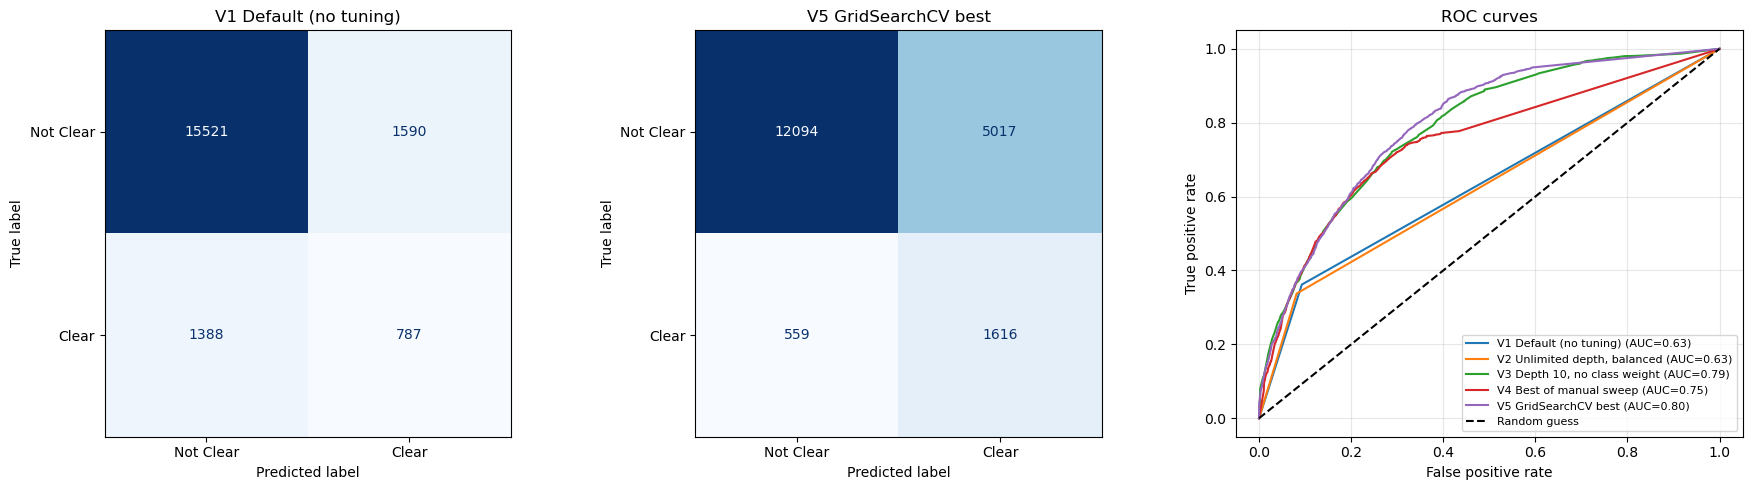

In [34]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, nm in zip(ax[:2], ["V1 Default (no tuning)", best_name]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, models[nm].predict(X_test)),
                           display_labels=["Not Clear", "Clear"]).plot(ax=a, cmap="Blues", colorbar=False)
    a.set_title(nm)
for nm, m in models.items():
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    ax[2].plot(fpr, tpr, label=f"{nm} (AUC={results_df.loc[nm, 'ROC AUC']:.2f})")
ax[2].plot([0, 1], [0, 1], "k--", label="Random guess")
ax[2].set_xlabel("False positive rate"); ax[2].set_ylabel("True positive rate")
ax[2].set_title("ROC curves"); ax[2].legend(fontsize=8); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

In [35]:
final_model = DecisionTreeClassifier(
    max_depth=20,            # 20 questions
    min_samples_leaf=50,     # leaf 50 hours
    criterion="gini",        # split quality measure
    class_weight="balanced",
    random_state=RANDOM_STATE)
final_model.fit(X_train, y_train)

identical = (final_model.predict(X_test) == grid.best_estimator_.predict(X_test)).all()
print("Same predictions as the GridSearchCV best model:", identical)
final_model

Same predictions as the GridSearchCV best model: True


,criterion,'gini'
,splitter,'best'
,max_depth,20
,min_samples_split,2
,min_samples_leaf,50
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,'balanced'


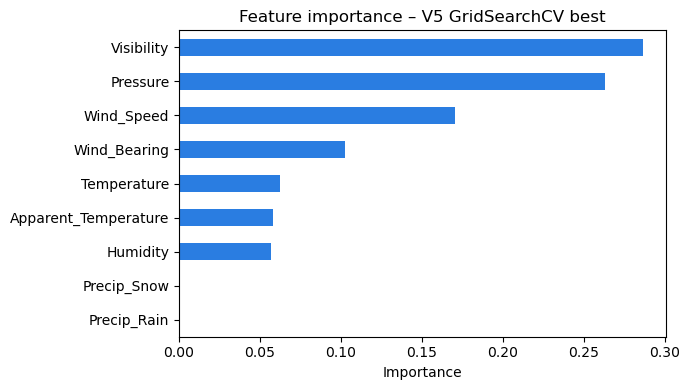

In [36]:
imp = pd.Series(best_model.feature_importances_, index=X.columns).sort_values()
plt.figure(figsize=(7, 4))
imp.plot(kind="barh", color="#2a7de1")
plt.title(f"Feature importance – {best_name}"); plt.xlabel("Importance"); plt.tight_layout(); plt.show()

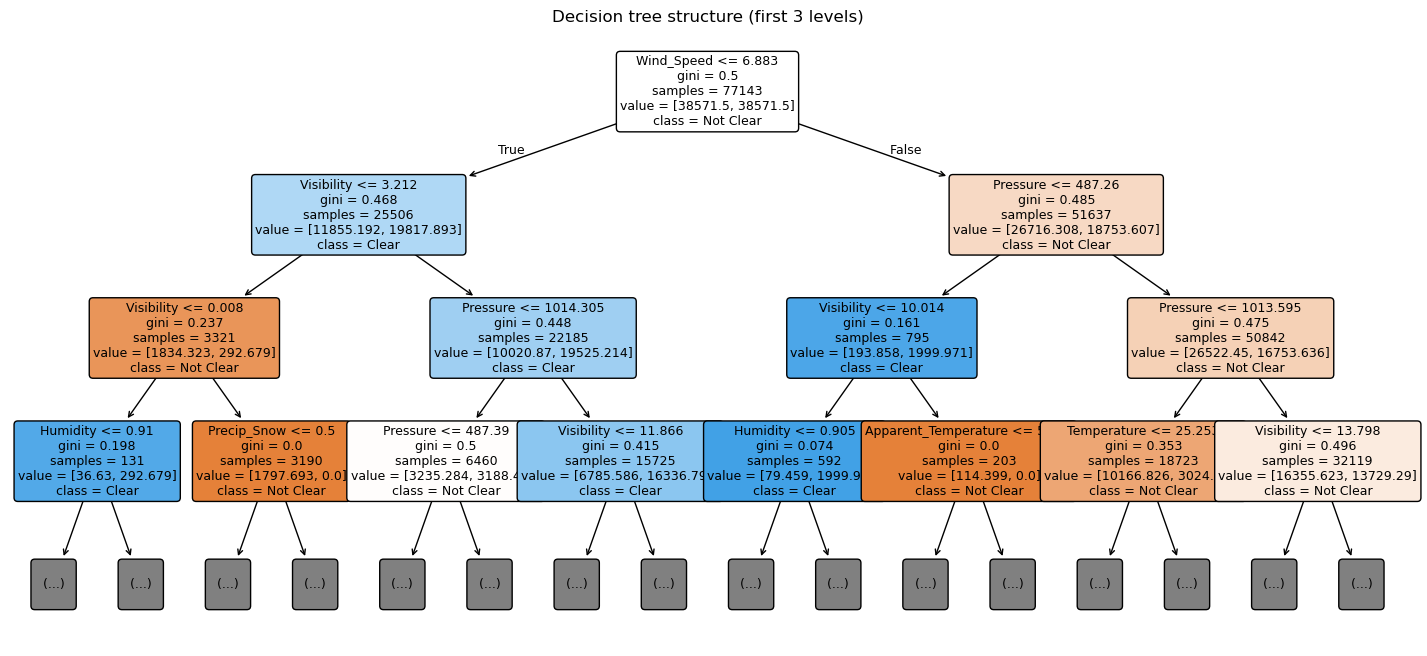

In [37]:
# Top of the chosen tree only (max_depth=3 in the plot) so it stays readable
plt.figure(figsize=(18, 8))
plot_tree(best_model, feature_names=list(X.columns), class_names=["Not Clear", "Clear"],
          max_depth=3, filled=True, rounded=True, fontsize=9)
plt.title("Decision tree structure (first 3 levels)")
plt.show()

Variance explained by 2 components: 0.543


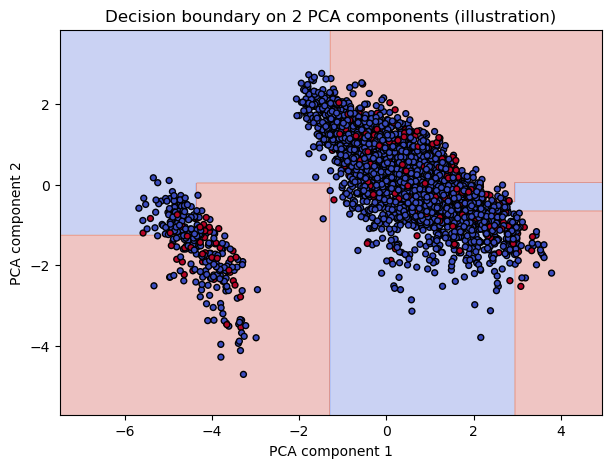

In [38]:
pca_scaler = StandardScaler().fit(X_train)
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(pca_scaler.transform(X_train))
Xtr_p = pca.transform(pca_scaler.transform(X_train))
Xte_p = pca.transform(pca_scaler.transform(X_test))
print("Variance explained by 2 components:", pca.explained_variance_ratio_.sum().round(3))

tree_p = DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=RANDOM_STATE).fit(Xtr_p, y_train)
xx, yy = np.meshgrid(np.linspace(Xte_p[:, 0].min() - 1, Xte_p[:, 0].max() + 1, 400),
                     np.linspace(Xte_p[:, 1].min() - 1, Xte_p[:, 1].max() + 1, 400))
Z = tree_p.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

idx = np.random.RandomState(RANDOM_STATE).choice(len(Xte_p), 3000, replace=False) 
plt.figure(figsize=(7, 5))
plt.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
plt.scatter(Xte_p[idx, 0], Xte_p[idx, 1], c=y_test.values[idx], cmap="coolwarm", edgecolors="k", s=18)
plt.title("Decision boundary on 2 PCA components (illustration)")
plt.xlabel("PCA component 1"); plt.ylabel("PCA component 2"); plt.show()

In [39]:
order = X.sort_index().index  
cut = int(len(order) * 0.8)
tr_idx, te_idx = order[:cut], order[cut:]

chrono_model = DecisionTreeClassifier(**grid.best_params_, random_state=RANDOM_STATE)
row_chrono = evaluate(chrono_model, "Best params – chronological split",
                      X.loc[tr_idx], y.loc[tr_idx], X.loc[te_idx], y.loc[te_idx])
row_random = results_df.loc[["V5 GridSearchCV best"]].reset_index().iloc[0].to_dict()
row_random["Model"] = "Best params – random stratified split"
pd.DataFrame([row_random, row_chrono]).set_index("Model").round(3)


,Parameters,Accuracy,Precision,Recall,F1,ROC AUC
Model,,,,,,
Best params – random stratified split,"max_depth=20, min_samples_leaf=50, criterion=gini, class_weight=balanced",0.711,0.244,0.743,0.367,0.798
Best params – chronological split,"max_depth=20, min_samples_leaf=50, criterion=gini, class_weight=balanced",0.590,0.134,0.732,0.226,0.728
